In [1]:
import pandas as pd
import time
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier

1. DATA PREPROCESSING<br><br>
Pada bagian ini, kita akan melakukan beberapa langkah untuk mempersiapkan data sebelum digunakan untuk pelatihan model. Langkah-langkah tersebut meliputi: 
- Menghapus data duplikat
- Memisahkan fitur (X) dan target (y)
- Membagi data menjadi data latih dan data uji



In [2]:
data_path = 'Dataset.csv'
data = pd.read_csv(data_path)
data.head()

,Type,url_length,number_of_dots_in_url,having_repeated_digits_in_url,number_of_digits_in_url,number_of_special_char_in_url,number_of_hyphens_in_url,number_of_underline_in_url,number_of_slash_in_url,number_of_questionmark_in_url,...,having_digits_in_subdomain,number_of_digits_in_subdomain,having_repeated_digits_in_subdomain,having_path,path_length,having_query,having_fragment,having_anchor,entropy_of_url,entropy_of_domain
0,0,37,2,0,0,8,0,0,5,0,...,0,0,1,0,3,0,0,0,4.010412,2.751629
1,1,70,5,0,0,12,0,0,6,0,...,0,0,1,0,4,0,0,0,4.089470,3.532573
2,0,42,2,0,6,8,0,0,3,1,...,0,0,1,0,1,1,0,0,4.386016,3.344698
3,0,46,2,0,0,7,0,0,4,0,...,0,0,1,0,2,0,0,0,4.221947,3.189898
4,0,51,3,0,0,9,0,0,5,0,...,0,0,1,0,3,0,0,0,4.103538,2.952820


In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 247950 entries, 0 to 247949
Data columns (total 42 columns):
 #   Column                                     Non-Null Count   Dtype  
---  ------                                     --------------   -----  
 0   Type                                       247950 non-null  int64  
 1   url_length                                 247950 non-null  int64  
 2   number_of_dots_in_url                      247950 non-null  int64  
 3   having_repeated_digits_in_url              247950 non-null  int64  
 4   number_of_digits_in_url                    247950 non-null  int64  
 5   number_of_special_char_in_url              247950 non-null  int64  
 6   number_of_hyphens_in_url                   247950 non-null  int64  
 7   number_of_underline_in_url                 247950 non-null  int64  
 8   number_of_slash_in_url                     247950 non-null  int64  
 9   number_of_questionmark_in_url              247950 non-null  int64  
 10  number_o

In [4]:
data.isna().sum()

Type                                         0
url_length                                   0
number_of_dots_in_url                        0
having_repeated_digits_in_url                0
number_of_digits_in_url                      0
number_of_special_char_in_url                0
number_of_hyphens_in_url                     0
number_of_underline_in_url                   0
number_of_slash_in_url                       0
number_of_questionmark_in_url                0
number_of_equal_in_url                       0
number_of_at_in_url                          0
number_of_dollar_in_url                      0
number_of_exclamation_in_url                 0
number_of_hashtag_in_url                     0
number_of_percent_in_url                     0
domain_length                                0
number_of_dots_in_domain                     0
number_of_hyphens_in_domain                  0
having_special_characters_in_domain          0
number_of_special_characters_in_domain       0
having_digits

In [5]:
# cari duplikat data
data.duplicated().sum()

np.int64(118172)

In [6]:
clean_data = data.drop_duplicates()
clean_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 129778 entries, 0 to 247939
Data columns (total 42 columns):
 #   Column                                     Non-Null Count   Dtype  
---  ------                                     --------------   -----  
 0   Type                                       129778 non-null  int64  
 1   url_length                                 129778 non-null  int64  
 2   number_of_dots_in_url                      129778 non-null  int64  
 3   having_repeated_digits_in_url              129778 non-null  int64  
 4   number_of_digits_in_url                    129778 non-null  int64  
 5   number_of_special_char_in_url              129778 non-null  int64  
 6   number_of_hyphens_in_url                   129778 non-null  int64  
 7   number_of_underline_in_url                 129778 non-null  int64  
 8   number_of_slash_in_url                     129778 non-null  int64  
 9   number_of_questionmark_in_url              129778 non-null  int64  
 10  number_of_equ

In [7]:
clean_data.shape

(129778, 42)

In [8]:
clean_data.describe()

,Type,url_length,number_of_dots_in_url,having_repeated_digits_in_url,number_of_digits_in_url,number_of_special_char_in_url,number_of_hyphens_in_url,number_of_underline_in_url,number_of_slash_in_url,number_of_questionmark_in_url,...,having_digits_in_subdomain,number_of_digits_in_subdomain,having_repeated_digits_in_subdomain,having_path,path_length,having_query,having_fragment,having_anchor,entropy_of_url,entropy_of_domain
count,129778.000000,129778.000000,129778.000000,129778.000000,129778.000000,129778.000000,129778.000000,129778.000000,129778.000000,129778.000000,...,129778.000000,129778.000000,129778.0,129778.0,129778.000000,129778.000000,129778.000000,129778.000000,129778.000000,129778.000000
mean,0.485622,60.333053,2.889912,0.170560,4.728575,10.454823,0.733799,0.217926,4.798610,0.157523,...,0.072909,0.269953,1.0,0.0,2.628812,0.124744,0.002312,0.000655,4.279462,3.413770
std,0.499795,29.959392,1.706060,0.376126,10.141365,4.650383,1.379149,0.694862,1.803069,0.448893,...,0.259988,1.437276,0.0,0.0,1.636540,0.330429,0.048024,0.025584,0.336509,0.386145
min,0.000000,12.000000,0.000000,0.000000,0.000000,4.000000,0.000000,0.000000,2.000000,0.000000,...,0.000000,0.000000,1.0,0.0,0.000000,0.000000,0.000000,0.000000,2.648939,1.386274
25%,0.000000,40.000000,2.000000,0.000000,0.000000,8.000000,0.000000,0.000000,4.000000,0.000000,...,0.000000,0.000000,1.0,0.0,2.000000,0.000000,0.000000,0.000000,4.057313,3.180833
50%,0.000000,52.000000,3.000000,0.000000,0.000000,9.000000,0.000000,0.000000,4.000000,0.000000,...,0.000000,0.000000,1.0,0.0,2.000000,0.000000,0.000000,0.000000,4.233007,3.421928
75%,1.000000,72.000000,3.000000,0.000000,4.000000,12.000000,1.000000,0.000000,5.000000,0.000000,...,0.000000,0.000000,1.0,0.0,3.000000,0.000000,0.000000,0.000000,4.464220,3.642490
max,1.000000,191.000000,28.000000,1.000000,144.000000,75.000000,23.000000,47.000000,30.000000,17.000000,...,1.000000,44.000000,1.0,0.0,28.000000,1.000000,1.000000,1.000000,5.866327,4.957323


In [9]:
from sklearn.model_selection import train_test_split
X = clean_data.drop(columns=["Type"])
y = clean_data["Type"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [10]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

classifiers = {
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42)),
    'Random Forest': make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)),
    'Gradient Boosting': make_pipeline(StandardScaler(), HistGradientBoostingClassifier(random_state=42)),
    'SVM': make_pipeline(StandardScaler(), SVC()),
    'KNN': make_pipeline(StandardScaler(), KNeighborsClassifier()),
    'XGBoost': make_pipeline(StandardScaler(), XGBClassifier(eval_metric='logloss', random_state=42))
}

In [11]:
accuracy_results = {}

In [12]:
# print("Memulai proses training dan evaluasi model...\n")
# print("-" * 50)

# for name, clf in classifiers.items():
#     clf.fit(X_train, y_train)
    
#     y_pred = clf.predict(X_test)
    
#     acc = accuracy_score(y_test, y_pred)
#     accuracy_results[name] = acc
    
#     print(f"Model: {name}")
#     print(f"Accuracy: {acc:.4f}")
#     print("Classification Report:")
#     print(classification_report(y_test, y_pred))
#     print("-" * 50)

In [13]:
hasil_evaluasi = []

In [14]:
from sklearn.metrics import f1_score
import time
print("Memulai proses komparasi model...\n")

for name, clf in classifiers.items():
    print(f"Sedang melatih model: {name} ...")
    
    start_time = time.time()
    
    clf.fit(X_train, y_train)
    
    y_pred = clf.predict(X_test)
    
    end_time = time.time()

    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    waktu = end_time - start_time

    print(f"Model: {name}")
    print(f"Accuracy: {acc:.4f}")
    print("Classification Report:")
    print(classification_report(y_test, y_pred))
    
    hasil_evaluasi.append({
        'Model': name,
        'Accuracy': round(acc * 100, 2), 
        'F1-Score': round(f1 * 100, 2),
        'Waktu Training (Detik)': round(waktu, 2)
    })

Memulai proses komparasi model...

Sedang melatih model: Logistic Regression ...
Model: Logistic Regression
Accuracy: 0.7993
Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.87      0.82     13351
           1       0.84      0.72      0.78     12605

    accuracy                           0.80     25956
   macro avg       0.81      0.80      0.80     25956
weighted avg       0.80      0.80      0.80     25956

Sedang melatih model: Random Forest ...
Model: Random Forest
Accuracy: 0.9028
Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.93      0.91     13351
           1       0.92      0.88      0.90     12605

    accuracy                           0.90     25956
   macro avg       0.90      0.90      0.90     25956
weighted avg       0.90      0.90      0.90     25956

Sedang melatih model: Gradient Boosting ...
Model: Gradient Boosting
Accuracy: 0.8878
Classificat

In [15]:
df_hasil = pd.DataFrame(hasil_evaluasi)

df_hasil = df_hasil.sort_values(by='Accuracy', ascending=False).reset_index(drop=True)

print("\n=== PERBANDINGAN MODEL ===")
display(df_hasil)


=== PERBANDINGAN MODEL ===


,Model,Accuracy,F1-Score,Waktu Training (Detik)
0,Random Forest,90.28,89.78,2.86
1,XGBoost,89.68,89.05,0.55
2,Gradient Boosting,88.78,88.09,0.89
3,KNN,87.91,87.15,2.27
4,SVM,86.99,86.00,333.02
5,Logistic Regression,79.93,77.80,1.54


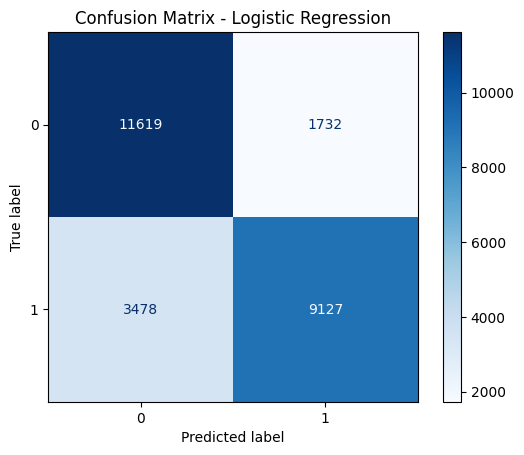

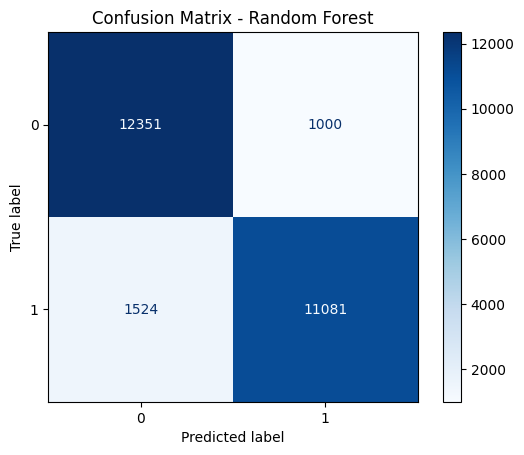

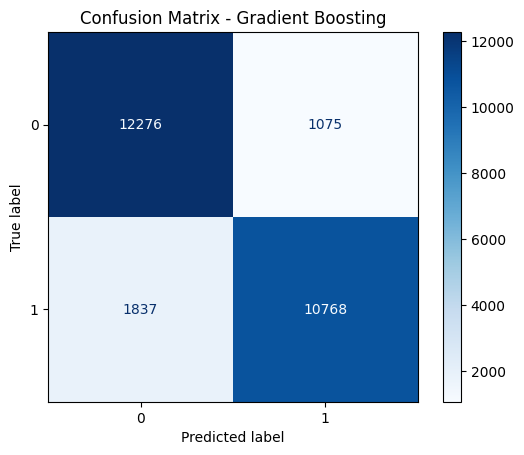

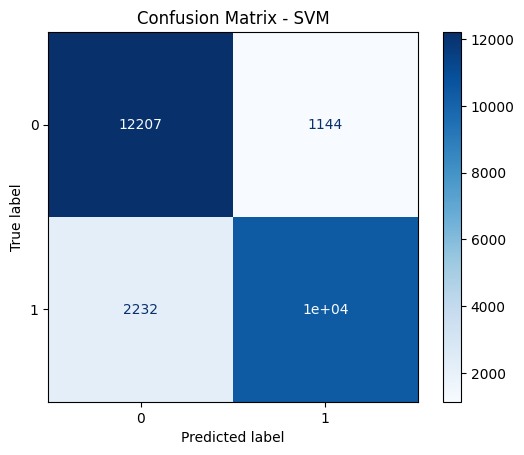

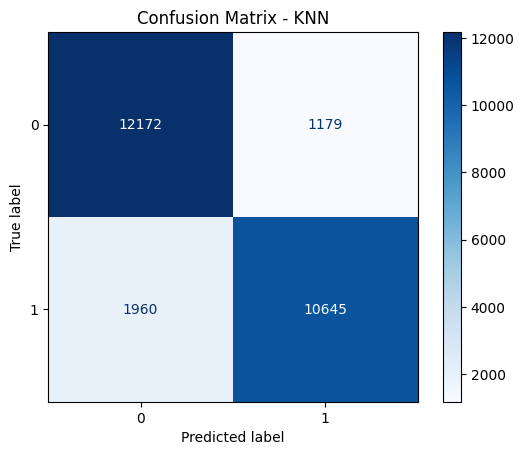

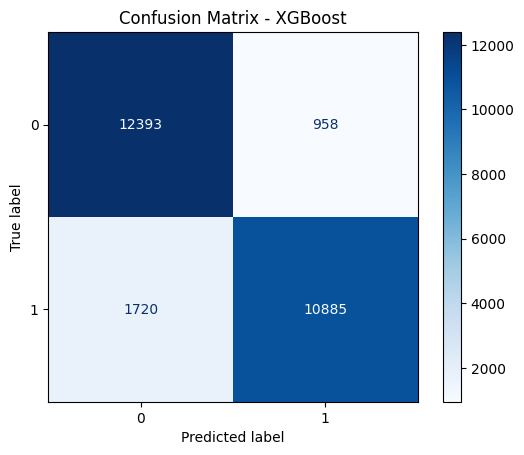

In [16]:
# conffusion matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
for name, clf in classifiers.items():
    y_pred = clf.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=clf.classes_)
    disp.plot(cmap=plt.cm.Blues)
    plt.title(f'Confusion Matrix - {name}')
    plt.show()

In [17]:
# # clasification matrix
# from sklearn.metrics import confusion_matrix
# import seaborn as sns
# import matplotlib.pyplot as plt

In [18]:
# print("\n=== Rangkuman Akurasi ===")
# sorted_results = dict(sorted(accuracy_results.items(), key=lambda item: item[1], reverse=True))

# for name, acc in sorted_results.items():
#     print(f"{name:<20} : {acc:.4f}")